# 01 · Qualidade e preparação dos dados

**Projeto 1 · Tech Challenge – Fase 1 · POSTECH Data Analytics (FIAP)**
Matheus Benjamin Aquino Silva
*Trilha do projeto: o que fazer para as vendas da Olist crescerem cada vez mais?*

**Pergunta deste notebook:** *dá para confiar nos dados?*

Antes de falar de crescimento, entrega ou recompra, o estudo precisa de uma base confiável. É como conferir os ingredientes antes de cozinhar: se a farinha estiver estragada, não adianta a receita ser boa. Este notebook abre os 9 arquivos da Olist um por um, procura os problemas e monta as duas bases que todos os outros notebooks usam.

**Perguntas que o notebook responde**

| Bloco | Perguntas | Seção |
|---|---|---|
| Arquivos | P1. Quais são os 9 arquivos e o que cada um guarda? · P2. Existe linha repetida? | 1, 2 e 3 |
| Valores vazios | P3. Onde estão os nulos, e eles fazem sentido? | 4 |
| Ligações | P4. Como as tabelas se conectam, e o que acontece se forem juntadas sem cuidado? | 5 |
| Números | P5. Quais variáveis numéricas andam juntas? | 6 |
| Inconsistências | P6. Que outros problemas mudam os números (meses incompletos, datas trocadas, cliente repetido, preço fora da curva)? | 7 |
| Bases finais | P7. Como ficam as bases de pedidos e de itens, e onde elas são salvas? | 8 e 9 |
| Fechamento | P8. Quais decisões foram tomadas, e a base é confiável? | 10 |

**O que são as decisões D1 a D9:** sempre que um problema pode mudar um número (a receita, o prazo, a recompra), a regra escolhida para tratá-lo vira uma **decisão numerada**. Assim, qualquer pessoa sabe exatamente o que foi feito e por quê. A lista completa está no fim do notebook e em `docs/qualidade_dados.md`.

**Estrutura de pastas usada**

| Pasta | Conteúdo |
|---|---|
| `data/raw/` | os 9 arquivos originais da Olist. Podem estar em **`.csv`** (versão completa, entregue na FIAP) ou em **`.csv.zip`** (versão compactada do GitHub): o notebook reconhece os dois formatos sozinho |
| `notebooks/PASTA/` | alternativa: se os CSVs estiverem nesta pasta, ela é usada primeiro |
| `src/` | regras de negócio (`config.py`, `dados.py`), dados externos (`externos.py`) e padrão visual dos gráficos (`viz.py`) |
| `data/processed/` | as duas bases finais, `pedidos` e `itens` (saída deste notebook e entrada dos notebooks 02 a 05) |
| `reports/figures/` | os gráficos salvos |

**Como ler este notebook:** cada etapa segue o mesmo padrão. Um texto curto explica o objetivo, a célula de código executa e um bloco **Leitura** interpreta o resultado e registra a decisão tomada. Assim dá para refazer o raciocínio do início ao fim.

Pergunta que orienta o projeto inteiro: **a Olist cresce de forma sustentável, e o que trava a satisfação e a recompra do cliente?**

## 1. Bibliotecas, caminhos e arquivos (P1)
O primeiro passo prepara o ambiente, em quatro partes:

| Parte | O que faz | Por quê |
|---|---|---|
| Raiz do projeto | Procura a pasta que contém `src/` | Os caminhos funcionam em qualquer computador, sem endereço fixo como `C:\Users\...` |
| Módulos do projeto | Importa `config`, `dados` e `viz` | As regras e o padrão dos gráficos ficam num lugar só |
| Pasta dos dados | Procura os arquivos em `notebooks/PASTA/` e, se não achar, em `data/raw/` | Funciona tanto no computador do autor quanto em quem baixar o projeto |
| Formato dos dados | Aceita os 9 arquivos em `.csv` **ou** em `.csv.zip` | É uma "chave de duas posições": na entrega da FIAP vão os CSVs completos; no GitHub, a versão compactada. O código percebe qual existe e segue |

No fim, a célula lista os arquivos encontrados, com formato e tamanho, **antes** de ler qualquer conteúdo.

In [1]:
# ============================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

# ============================================================
# LOCALIZAR A RAIZ DO PROJETO
# ============================================================

RAIZ = Path.cwd().resolve()

while not (RAIZ / "src").is_dir():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError(
            "Não foi possível localizar a pasta 'src'. "
            "Verifique se o Jupyter está aberto dentro do projeto."
        )
    RAIZ = RAIZ.parent

# Adicionar raiz ao caminho de importação
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# ============================================================
# IMPORTAR MÓDULOS DO PROJETO
# ============================================================

from src import config, dados, viz

# ============================================================
# CONFIGURAÇÕES DE VISUALIZAÇÃO
# ============================================================

viz.aplicar_estilo()

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

# ============================================================
# FUNÇÕES DE FORMATAÇÃO (PADRÃO BRASILEIRO)
# ============================================================

def fmt(valor):
    """Inteiro com ponto de milhar: 99441 -> 99.441"""
    return f"{valor:,}".replace(",", ".")

def pct_br(fracao, casas=1):
    """Fração em percentual com vírgula: 0.179 -> 17,9%"""
    return f"{100 * fracao:.{casas}f}%".replace(".", ",")

# ============================================================
# LOCALIZAR PASTA DOS ARQUIVOS ORIGINAIS
# ============================================================

# Ordem de procura: notebooks/PASTA e, se não existir, data/raw
# O código aceita os dois jeitos de guardar os 9 arquivos da Olist:
#   - versão completa (entrega na FIAP): os 9 arquivos .csv soltos
#   - versão compactada (repositório do GitHub): os 9 arquivos .csv.zip
# Se existirem os dois, vale o .csv. O pandas abre o .zip direto, sem descompactar à mão.
candidatas = [RAIZ / "notebooks" / "PASTA", RAIZ / "data" / "raw"]


def tem_arquivos_olist(pasta):
    """True se a pasta tem os CSVs da Olist, soltos (.csv) ou compactados (.csv.zip)."""
    return pasta.is_dir() and (any(pasta.rglob("*.csv")) or any(pasta.rglob("*.csv.zip")))


PASTA = next((p for p in candidatas if tem_arquivos_olist(p)), None)

if PASTA is None:
    raise FileNotFoundError(
        "Nenhum CSV encontrado (nem .csv nem .csv.zip). Pastas verificadas: "
        + ", ".join(str(p.relative_to(RAIZ)) for p in candidatas)
    )

PASTA_PROCESSADOS = RAIZ / "data" / "processed"

print("=" * 60)
print("CONFIGURAÇÃO DO PROJETO")
print("=" * 60)
print(f"Raiz do projeto:      {RAIZ}")
print(f"CSVs originais:       {PASTA.relative_to(RAIZ)}")
print(f"Saída (bases finais): {PASTA_PROCESSADOS.relative_to(RAIZ)}")

# ============================================================
# INVENTÁRIO DOS ARQUIVOS CSV (ainda sem ler o conteúdo)
# ============================================================

# a chave é sempre o nome do CSV; o caminho pode ser o .csv ou o .csv.zip
arquivos_csv = {}
for arquivo in sorted(PASTA.rglob("*.csv")) + sorted(PASTA.rglob("*.csv.zip")):
    arquivos_csv.setdefault(arquivo.name.removesuffix(".zip"), arquivo)

FORMATO = "compactado (.csv.zip)" if any(c.suffix == ".zip" for c in arquivos_csv.values()) else "CSV (.csv)"
print(f"Formato dos arquivos:  {FORMATO}")

inventario = pd.DataFrame([
    {
        "arquivo": nome,
        "formato": "csv.zip" if caminho.suffix == ".zip" else "csv",
        "subpasta": "(raiz)" if caminho.parent == PASTA else str(caminho.parent.relative_to(PASTA)),
        "tamanho (MB)": round(caminho.stat().st_size / 1024**2, 1),
    }
    for nome, caminho in arquivos_csv.items()
])

print("\n" + "=" * 60)
print(f"ARQUIVOS CSV ENCONTRADOS: {len(arquivos_csv)}")
print("=" * 60)
display(inventario)

,arquivo,formato,subpasta,tamanho (MB)
0,olist_customers_dataset.csv,csv,(raiz),8.6
1,olist_geolocation_dataset.csv,csv,(raiz),58.4
2,olist_order_items_dataset.csv,csv,(raiz),14.7
3,olist_order_payments_dataset.csv,csv,(raiz),5.5
4,olist_order_reviews_dataset.csv,csv,(raiz),13.8
5,olist_orders_dataset.csv,csv,(raiz),16.8
6,olist_products_dataset.csv,csv,(raiz),2.3
7,olist_sellers_dataset.csv,csv,(raiz),0.2
8,product_category_name_translation.csv,csv,(raiz),0.0


CONFIGURAÇÃO DO PROJETO
Raiz do projeto:      /home/claude/projeto-1-tech-challenge
CSVs originais:       data/raw
Saída (bases finais): data/processed
Formato dos arquivos:  CSV (.csv)

ARQUIVOS CSV ENCONTRADOS: 9


## 2. Leitura dos 9 CSVs, um por um (P1 e P2)
Cada arquivo é carregado numa variável própria (`clientes`, `pedidos_raw`, `itens_raw`...), para ser olhado sozinho antes de qualquer junção.

A função `ler()` procura o arquivo pelo nome no inventário da etapa anterior. Por isso não importa se ele está numa subpasta nem se está compactado: o pandas abre o `.csv` e o `.csv.zip` do mesmo jeito.

A tabela de resumo mostra, para cada base: número de linhas, de colunas, de **linhas repetidas** (linhas inteiras idênticas) e a memória ocupada.

In [2]:
# ============================================================
# LEITURA DAS BASES ORIGINAIS - OLIST
# ============================================================

def ler(nome_arquivo):
    """Lê um CSV original pelo nome, usando o inventário montado na etapa 1 (.csv ou .csv.zip)."""
    caminho = arquivos_csv.get(nome_arquivo)
    if caminho is None:
        raise FileNotFoundError(
            f"Arquivo não encontrado: {nome_arquivo}\n"
            f"Pasta pesquisada: {PASTA}"
        )
    return pd.read_csv(caminho, low_memory=False)

# ============================================================
# CARREGAMENTO DAS BASES
# ============================================================

clientes    = ler("olist_customers_dataset.csv")
pedidos_raw = ler("olist_orders_dataset.csv")
itens_raw   = ler("olist_order_items_dataset.csv")
pagamentos  = ler("olist_order_payments_dataset.csv")
avaliacoes  = ler("olist_order_reviews_dataset.csv")
produtos    = ler("olist_products_dataset.csv")
vendedores  = ler("olist_sellers_dataset.csv")
geo         = ler("olist_geolocation_dataset.csv")
traducao    = ler("product_category_name_translation.csv")

# ============================================================
# ORGANIZAÇÃO DAS BASES
# ============================================================

bases = {
    "clientes": clientes,
    "pedidos": pedidos_raw,
    "itens": itens_raw,
    "pagamentos": pagamentos,
    "avaliacoes": avaliacoes,
    "produtos": produtos,
    "vendedores": vendedores,
    "geolocalizacao": geo,
    "traducao": traducao,
}

# ============================================================
# RESUMO DAS BASES
# ============================================================

resumo = pd.DataFrame({
    "linhas": {n: len(df) for n, df in bases.items()},
    "colunas": {n: df.shape[1] for n, df in bases.items()},
    "linhas duplicadas": {n: df.duplicated().sum() for n, df in bases.items()},
    "memória (MB)": {n: round(df.memory_usage(deep=True).sum() / 1024**2, 1) for n, df in bases.items()},
})

display(resumo)
print(f"Bases carregadas: {len(bases)}")

,linhas,colunas,linhas duplicadas,memória (MB)
clientes,99441,5,0,26.6
pedidos,99441,8,0,52.9
itens,112650,7,0,36.0
pagamentos,103886,5,0,16.2
avaliacoes,99224,7,0,39.1
produtos,32951,9,0,6.3
vendedores,3095,4,0,0.6
geolocalizacao,1000163,5,261831,130.3
traducao,71,2,0,0.0


Bases carregadas: 9


**Leitura (P1 e P2):**

| Pergunta | Resultado | Interpretação |
|---|---|---|
| Qual é a maior tabela? | **Geolocalização**, com cerca de 1 milhão de linhas | É um catálogo de coordenadas por CEP, com vários pontos para o mesmo CEP |
| Existe linha repetida? | Só na geolocalização: cerca de **261 mil** linhas idênticas | Precisa de tratamento antes de juntar (decisão D8). As outras 8 tabelas não têm linha repetida |
| Já dá para ver alguma ligação? | `clientes` e `pedidos` têm o **mesmo número de linhas (99.441)** | Primeiro indício de que cada pedido tem exatamente um cliente (relação 1 para 1), o que a seção 5 confirma |

## 3. Início e fim de cada base (P1)
O `head()` mostra as primeiras linhas e o `tail()`, as últimas. Olhar as duas pontas ajuda a entender o formato de cada coluna, o tipo do dado (texto, número, data) e se o fim do arquivo traz alguma sujeira, como linha cortada ou total somado.

### clientes
**O que guarda:** quem comprou e onde mora (prefixo do CEP, cidade e UF).
**O que observar:** existem dois códigos de cliente. O `customer_id` identifica o cliente **naquele pedido** e muda a cada compra; o `customer_unique_id` identifica a **pessoa**. Para medir recompra, só o segundo serve (decisão D5).

In [3]:
display(clientes.head())
display(clientes.tail())
print(clientes.dtypes.to_string())

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS
99440,274fa6071e5e17fe303b9748641082c8,84732c5050c01db9b23e19ba39899398,6703,cotia,SP


customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str


### pedidos
**O que guarda:** o status do pedido e as datas de cada etapa: compra, aprovação do pagamento, postagem, entrega ao cliente e entrega prometida.
**O que observar:** as datas chegam como texto e precisam ser convertidas para data antes de qualquer conta de prazo.

In [4]:
display(pedidos_raw.head())
display(pedidos_raw.tail())
print(pedidos_raw.dtypes.to_string())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00
99440,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00


order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str


### itens
**O que guarda:** uma linha por item vendido, com produto, vendedor, preço, frete e prazo-limite de postagem.
**O que observar:** o mesmo pedido aparece várias vezes quando tem mais de um item. Somar sem cuidado multiplica a receita.

In [5]:
display(itens_raw.head())
display(itens_raw.tail())
print(itens_raw.dtypes.to_string())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72
112649,fffe41c64501cc87c801fd61db3f6244,1,350688d9dc1e75ff97be326363655e01,f7ccf836d21b2fb1de37564105216cc1,2018-06-12 17:10:13,43.00,12.79


order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64


### pagamentos
**O que guarda:** forma de pagamento, número de parcelas e valor pago.
**O que observar:** um pedido pode ter mais de uma forma de pagamento (cartão + voucher, por exemplo), então também aparece mais de uma vez.

In [6]:
display(pagamentos.head())
display(pagamentos.tail())
print(pagamentos.dtypes.to_string())

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


,order_id,payment_sequential,payment_type,payment_installments,payment_value
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54
103885,28bbae6599b09d39ca406b747b6632b1,1,boleto,1,191.58


order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64


### avaliacoes
**O que guarda:** a nota de 1 a 5 que o cliente deu, com título e comentário.
**O que observar:** título e comentário são opcionais, por isso aparecem vazios. A nota é o termômetro de satisfação usado no projeto inteiro.

In [7]:
display(avaliacoes.head())
display(avaliacoes.tail())
print(avaliacoes.dtypes.to_string())

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa,2018-03-01 00:00:00,2018-03-02 10:26:53


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super recomendo essa loja!",2018-03-22 00:00:00,2018-03-23 09:10:43
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13
99223,efe49f1d6f951dd88b51e6ccd4cc548f,90531360ecb1eec2a1fbb265a0db0508,1,NaN,"meu produto chegou e ja tenho que devolver, pois está com defeito , não segurar carga",2017-07-03 00:00:00,2017-07-03 21:01:49


review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str


### produtos
**O que guarda:** categoria, peso, medidas, nº de fotos e tamanho da descrição de cada produto.
**O que observar:** os nomes de duas colunas vêm com erro de grafia no original (`lenght` em vez de `length`). O nome foi mantido para não fugir do arquivo da Olist.

In [8]:
display(produtos.head())
display(produtos.tail())
print(produtos.dtypes.to_string())

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0
32950,106392145fca363410d287a815be6de4,cama_mesa_banho,58.0,309.0,1.0,2083.0,12.0,2.0,7.0


product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64


### vendedores
**O que guarda:** só o cadastro e a localização de cada vendedor (prefixo do CEP, cidade e UF).
**O que observar:** é com esse CEP, junto com o do cliente, que a distância da entrega é calculada.

In [9]:
display(vendedores.head())
display(vendedores.tail())
print(vendedores.dtypes.to_string())

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


,seller_id,seller_zip_code_prefix,seller_city,seller_state
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS
3094,9e25199f6ef7e7c347120ff175652c3b,12051,taubate,SP


seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str


### geolocalizacao
**O que guarda:** latitude e longitude de cada prefixo de CEP.
**O que observar:** o mesmo prefixo aparece com vários pontos diferentes. Para juntar com clientes e vendedores, cada CEP precisa virar **um ponto só** (decisão D8).

In [10]:
display(geo.head())
display(geo.tail())
print(geo.dtypes.to_string())

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
1000158,99950,-28.068639,-52.010705,tapejara,RS
1000159,99900,-27.877125,-52.224882,getulio vargas,RS
1000160,99950,-28.071855,-52.014716,tapejara,RS
1000161,99980,-28.388932,-51.846871,david canabarro,RS
1000162,99950,-28.070104,-52.018658,tapejara,RS


geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str


### traducao
**O que guarda:** o nome de cada categoria em português e em inglês.
**O que observar:** duas categorias que existem em `produtos` não aparecem aqui; a tradução delas é completada à mão (decisão D9).

In [11]:
display(traducao.head())
display(traducao.tail())
print(traducao.dtypes.to_string())

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


,product_category_name,product_category_name_english
66,flores,flowers
67,artes_e_artesanato,arts_and_craftmanship
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes
70,seguros_e_servicos,security_and_services


product_category_name            str
product_category_name_english    str


## 4. Onde estão os nulos (P3)
Um **valor nulo** é uma célula vazia. Nem todo vazio é erro: um pedido que ainda não chegou não tem data de entrega, e isso está certo. O objetivo aqui é separar o vazio **esperado** do vazio **problemático**.

Em vez de ler os números coluna por coluna, o gráfico mostra o % de nulos só nas colunas que têm algum.

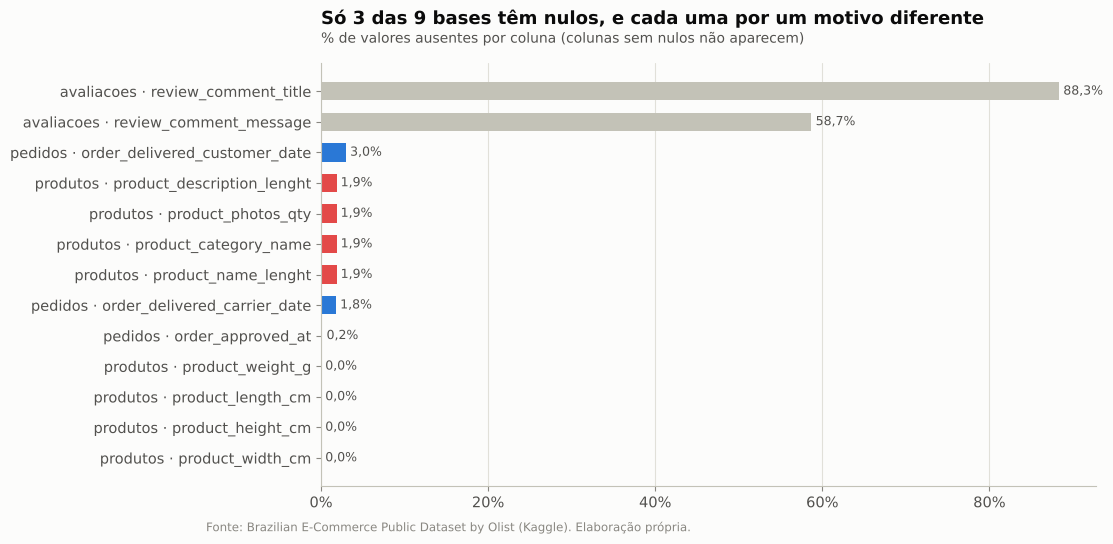

In [12]:
nulos = []
for nome, df in bases.items():
    pct = df.isna().mean() * 100
    for coluna, valor in pct[pct > 0].items():
        nulos.append({"base": nome, "coluna": coluna, "pct_nulos": valor})
nulos = pd.DataFrame(nulos).sort_values("pct_nulos")

fig, ax = plt.subplots(figsize=(10, 5.5))
cores = {"avaliacoes": viz.CONTEXTO, "pedidos": viz.DESTAQUE, "produtos": viz.ALERTA}
ax.barh(nulos["base"] + " · " + nulos["coluna"], nulos["pct_nulos"],
        color=[cores[b] for b in nulos["base"]], height=0.6)
for y, v in enumerate(nulos["pct_nulos"]):
    ax.text(v + 0.5, y, f"{v:.1f}%".replace(".", ","), va="center", fontsize=9, color=viz.TINTA_SECUNDARIA)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(viz.formato_pct())
viz.titulo(ax, "Só 3 das 9 bases têm nulos, e cada uma por um motivo diferente",
           "% de valores ausentes por coluna (colunas sem nulos não aparecem)")
viz.fonte(fig)
viz.salvar_figura(fig, "01_nulos")
plt.show()

**Leitura (P3):**

| Tabela | O que está vazio | É problema? | O que foi feito |
|---|---|---|---|
| Avaliações | Título (88%) e comentário (59%) | Não: o cliente não é obrigado a escrever | Nenhum tratamento |
| Pedidos | Datas de aprovação, postagem e entrega | Depende: o vazio precisa bater com o status do pedido | Conferido na tabela logo abaixo |
| Produtos | Categoria em 610 produtos (1,9%) e medidas em 2 | Pequeno | A categoria vazia vira "sem categoria", para não perder esses produtos |

In [13]:
tem_data_entrega = pedidos_raw["order_delivered_customer_date"].notna().rename("tem data de entrega")
pd.crosstab(pedidos_raw["order_status"], tem_data_entrega, margins=True)

tem data de entrega,False,True,All
order_status,,,
approved,2,0,2
canceled,619,6,625
created,5,0,5
delivered,8,96470,96478
invoiced,314,0,314
processing,301,0,301
shipped,1107,0,1107
unavailable,609,0,609
All,2965,96476,99441


**Leitura:** a tabela cruza o status do pedido com a existência da data de entrega. Quase todo pedido sem data de entrega de fato não foi entregue, o que é coerente. Sobram 8 pedidos "delivered" (entregues) **sem** data e 6 "canceled" (cancelados) **com** data.

**Decisão D6:** nas contas de prazo e atraso entram só os pedidos entregues **e** com a data registrada.

## 5. Como as tabelas se relacionam, antes do merge (P4)
**Merge** é juntar duas tabelas por uma coluna em comum, como procurar o nome de um aluno na lista de chamada e na lista de notas para montar o boletim. O cuidado é saber **quantas vezes** cada chave aparece de cada lado:

- **1 para 1:** cada pedido tem um cliente. Juntar é seguro.
- **1 para N:** um pedido tem vários itens. Se o pedido for juntado direto, ele se repete uma vez por item, e a receita é contada várias vezes.

Para cada ligação, a tabela abaixo responde a três perguntas:
1. **Qual coluna as duas tabelas têm em comum?** (a chave)
2. **Quantas linhas existem por chave de cada lado?** Se for mais de 1, o merge multiplica linhas.
3. **Quanto das chaves de um lado existe do outro?** Se for menos de 100%, algum registro fica sem par.

In [14]:
def relacao(esq, dir_, chave_esq, chave_dir, nome_esq, nome_dir):
    return {
        "ligação": f"{nome_esq} → {nome_dir}",
        "chave": chave_esq if chave_esq == chave_dir else "CEP (zip_code_prefix)",
        "máx. por chave (esq.)": esq[chave_esq].value_counts().max(),
        "máx. por chave (dir.)": dir_[chave_dir].value_counts().max(),
        "% encontrada na dir.": 100 * esq[chave_esq].isin(dir_[chave_dir]).mean(),
    }

# (tabela esq., tabela dir., chave esq., chave dir., nome esq., nome dir., colunas de exemplo esq., dir.)
LIGACOES = [
    (pedidos_raw, clientes,   "customer_id", "customer_id", "pedidos", "clientes",
     ["order_status"], ["customer_unique_id", "customer_state"]),
    (pedidos_raw, itens_raw,  "order_id", "order_id", "pedidos", "itens",
     ["order_status"], ["order_item_id", "price"]),
    (pedidos_raw, pagamentos, "order_id", "order_id", "pedidos", "pagamentos",
     ["order_status"], ["payment_sequential", "payment_type", "payment_value"]),
    (pedidos_raw, avaliacoes, "order_id", "order_id", "pedidos", "avaliacoes",
     ["order_status"], ["review_id", "review_score"]),
    (itens_raw, produtos,     "product_id", "product_id", "itens", "produtos",
     ["price"], ["product_category_name"]),
    (itens_raw, vendedores,   "seller_id", "seller_id", "itens", "vendedores",
     ["price"], ["seller_city", "seller_state"]),
    (produtos.dropna(subset=["product_category_name"]), traducao,
     "product_category_name", "product_category_name", "produtos", "traducao",
     ["product_id"], ["product_category_name_english"]),
    (clientes, geo,   "customer_zip_code_prefix", "geolocation_zip_code_prefix", "clientes", "geolocalizacao",
     ["customer_city"], ["geolocation_lat", "geolocation_lng"]),
    (vendedores, geo, "seller_zip_code_prefix", "geolocation_zip_code_prefix", "vendedores", "geolocalizacao",
     ["seller_city"], ["geolocation_lat", "geolocation_lng"]),
]

ligacoes = pd.DataFrame([relacao(*l[:6]) for l in LIGACOES]).set_index("ligação")
ligacoes.round(2)

,chave,máx. por chave (esq.),máx. por chave (dir.),% encontrada na dir.
ligação,,,,
pedidos → clientes,customer_id,1,1,100.00
pedidos → itens,order_id,1,21,99.22
pedidos → pagamentos,order_id,1,29,100.00
pedidos → avaliacoes,order_id,1,3,99.23
itens → produtos,product_id,527,1,100.00
itens → vendedores,seller_id,2033,1,100.00
produtos → traducao,product_category_name,3029,1,99.96
clientes → geolocalizacao,CEP (zip_code_prefix),142,1146,99.72
vendedores → geolocalizacao,CEP (zip_code_prefix),49,1146,99.77


**Leitura (P4): a tabela define como cada merge é feito.**

| Ligação | Tipo | O que fazer |
|---|---|---|
| pedidos → clientes | 1 para 1 | Juntar direto |
| pedidos → itens / pagamentos / avaliações | 1 para N (até 21 itens, 29 pagamentos e 3 avaliações por pedido) | **Resumir para 1 linha por pedido antes de juntar.** Um merge direto repetiria o pedido e multiplicaria a receita |
| itens → produtos / vendedores | N para 1, casando 100% | Juntar direto |
| produtos → tradução | 2 categorias sem par | Completar a tradução à mão |
| CEP → geolocalização | até 1.146 linhas para o mesmo CEP; menos de 1% dos CEPs sem coordenada | **Reduzir cada CEP a 1 coordenada** antes; juntar direto explodiria a base |

### 5.1 Exemplos lado a lado
Para enxergar a ligação na prática, alguns códigos que existem nas duas tabelas são sorteados e mostrados lado a lado. A coluna `linha` indica a posição original em cada CSV. Quando a relação é 1 para N, a linha da esquerda se repete ao lado de cada par: é exatamente a "multiplicação" que o merge faria.

In [15]:
def lado_a_lado(esq, dir_, chave_esq, chave_dir, nome_esq, nome_dir,
                cols_esq=(), cols_dir=(), n=5, semente=7, max_por_chave=None):
    comuns = pd.Series(esq[chave_esq][esq[chave_esq].isin(dir_[chave_dir])].unique())
    ids = comuns.sample(min(n, len(comuns)), random_state=semente).tolist()

    a = esq[esq[chave_esq].isin(ids)][[chave_esq, *cols_esq]].copy()
    a.insert(0, "linha", a.index)
    b = dir_[dir_[chave_dir].isin(ids)][[chave_dir, *cols_dir]].copy()
    b.insert(0, "linha", b.index)
    if max_por_chave:                      # geolocalização: limita as linhas exibidas por CEP
        a = a.groupby(chave_esq).head(max_por_chave)
        b = b.groupby(chave_dir).head(max_por_chave)

    a.columns = [f"E|{c}" for c in a.columns]
    b.columns = [f"D|{c}" for c in b.columns]
    junto = a.merge(b, left_on=f"E|{chave_esq}", right_on=f"D|{chave_dir}")
    junto = junto.sort_values([f"E|{chave_esq}", "E|linha", "D|linha"]).reset_index(drop=True)
    junto.columns = pd.MultiIndex.from_tuples(
        [(nome_esq if c.startswith("E|") else nome_dir, c[2:]) for c in junto.columns])
    return junto

for esq, dir_, ch_esq, ch_dir, n_esq, n_dir, c_esq, c_dir in LIGACOES:
    geo_ = n_dir == "geolocalizacao"
    print(f"\n{n_esq} → {n_dir}  ({ch_esq} = {ch_dir})")
    display(lado_a_lado(esq, dir_, ch_esq, ch_dir, n_esq, n_dir, c_esq, c_dir,
                        n=2 if geo_ else 5, max_por_chave=3 if geo_ else None))

pedidos                                                clientes                                                                                   
    linha                       customer_id order_status    linha                       customer_id                customer_unique_id customer_state
0   48017  39b0a374b8bbb7f162a55a042a3c2f50    delivered    43244  39b0a374b8bbb7f162a55a042a3c2f50  e3a780e68fefbc2ff9d44a54d4d25779             SE
1   77007  4314121fb5cfec01588f42ef6bbb3db3    delivered    33022  4314121fb5cfec01588f42ef6bbb3db3  7aee89d30d522a26e21dd6931bcacf98             SP
2   53647  7d9fd47eeb21776ed93f070d71499e0a    delivered    10791  7d9fd47eeb21776ed93f070d71499e0a  c735c714dbe80672320182bb48bba3ba             MG
3   34012  9709ffa24c12b2fb47c3ec2470b16952    delivered    38455  9709ffa24c12b2fb47c3ec2470b16952  c0019b5eb8e0621d40453fb37a7f4ede             RS
4   32469  9dadc4bfa2ec469a923c2ac8ffdc3a0f    delivered     7563  9dadc4bfa2ec469a923c2ac8ffdc3a0f  d9058ef529d2c65e426d6d84ff11e838             SP

pedidos                                                 itens                                                         
    linha                          order_id order_status  linha                          order_id order_item_id    price
0   14805  0897cfdc3612d0942f33b22a3dd9cd8c    delivered   3790  0897cfdc3612d0942f33b22a3dd9cd8c             1   389.00
1   36770  0f121110b75ef7c38c79d67833c49830    delivered   6655  0f121110b75ef7c38c79d67833c49830             1   760.00
2   29143  226bc0c2f038af61a10705e253ef0d6a    delivered  15110  226bc0c2f038af61a10705e253ef0d6a             1    39.90
3   30618  6a6c30136e870dc8e8338fbb826ee41e    delivered  46807  6a6c30136e870dc8e8338fbb826ee41e             1  1399.99
4     721  7b2f3756c235e93b2ad6330c54805401    delivered  54210  7b2f3756c235e93b2ad6330c54805401             1    63.99

pedidos                                                pagamentos                                                                                
    linha                          order_id order_status      linha                          order_id payment_sequential payment_type payment_value
0   84865  009ac365164f8e06f59d18a08045f6c4    delivered        285  009ac365164f8e06f59d18a08045f6c4                  5      voucher          8.75
1   84865  009ac365164f8e06f59d18a08045f6c4    delivered      15298  009ac365164f8e06f59d18a08045f6c4                  6      voucher          4.17
2   84865  009ac365164f8e06f59d18a08045f6c4    delivered      16053  009ac365164f8e06f59d18a08045f6c4                  1  credit_card          0.88
3   84865  009ac365164f8e06f59d18a08045f6c4    delivered      16459  009ac365164f8e06f59d18a08045f6c4                  2      voucher          4.50
4   84865  009ac365164f8e06f59d18a08045f6c4    delivered      32058  009ac365164f8e06f59d18a08045f6c4                  4      voucher          5.45
5   84865  009ac365164f8e06f59d18a08045f6c4    delivered      73837  009ac365164f8e06f59d18a08045f6c4                  3      voucher          8.25
6   34004  0e8a52f34b055d2027ea7807c20119c4    delivered      17297  0e8a52f34b055d2027ea7807c20119c4                  1  credit_card         91.79
7   68917  4568a2bce4050c7579e898eca38f8833    delivered      17391  4568a2bce4050c7579e898eca38f8833                  1  credit_card         55.28
8   73010  86cd4fa4ff90b76544cfbe330c5da54b    delivered       5866  86cd4fa4ff90b76544cfbe330c5da54b                  1       boleto         63.27
9   77007  f68550a60fc010eda8ef9a1e5cd4d651    delivered      52015  f68550a60fc010eda8ef9a1e5cd4d651                  1  credit_card        138.92

pedidos                                                avaliacoes                                                                                 
    linha                          order_id order_status      linha                          order_id                         review_id review_score
0   56839  4e724c7d98c212ac0bbca82b6d274f76    delivered       3132  4e724c7d98c212ac0bbca82b6d274f76  7828e22ec7f3dd35459e18424c08e4ae            1
1   98895  a9aa7a1967b25653be2df8c6bdba2fd2    delivered      92855  a9aa7a1967b25653be2df8c6bdba2fd2  64c73560861e71981257ffc8549ea177            5
2   37176  bf00ad2335cd5715823f0f1980a8e8ab    delivered      71559  bf00ad2335cd5715823f0f1980a8e8ab  1b97d6cd75e19e937ed56762701def6b            1
3   48524  cd974875c10f96dfe6a717e02c625feb    delivered      39647  cd974875c10f96dfe6a717e02c625feb  427543b37c35e775788d5b29bbbe762b            5
4     725  d0e9849de800fdb4cb3b5e6d42c6b367    delivered      96817  d0e9849de800fdb4cb3b5e6d42c6b367  f4503175538ce5fcbc71659cc7ae8daa            1

itens                                           produtos                                                                 
   linha                        product_id   price    linha                        product_id          product_category_name
0  46903  2d1ff2e44c1df1b288d32c02737d6f34  159.90    16337  2d1ff2e44c1df1b288d32c02737d6f34               moveis_decoracao
1  69897  2f8074adf7fe41641ddf0df320e6a7bb  220.00     3159  2f8074adf7fe41641ddf0df320e6a7bb                  esporte_lazer
2  88758  2f8074adf7fe41641ddf0df320e6a7bb  220.00     3159  2f8074adf7fe41641ddf0df320e6a7bb                  esporte_lazer
3  17142  4c1d9c97a7245db3b8d7a32fb4c02286  135.00    23443  4c1d9c97a7245db3b8d7a32fb4c02286         livros_interesse_geral
4  24464  4c1d9c97a7245db3b8d7a32fb4c02286  135.00    23443  4c1d9c97a7245db3b8d7a32fb4c02286         livros_interesse_geral
5  27517  4c1d9c97a7245db3b8d7a32fb4c02286  129.90    23443  4c1d9c97a7245db3b8d7a32fb4c02286         livros_interesse_geral
6  36660  4c1d9c97a7245db3b8d7a32fb4c02286  135.00    23443  4c1d9c97a7245db3b8d7a32fb4c02286         livros_interesse_geral
7  70640  695da2d1ee50ae5a8ad2085798a645ad   29.45    30792  695da2d1ee50ae5a8ad2085798a645ad  construcao_ferramentas_jardim
8  58748  dafc867209fb20b8331f1edaebc95b58  883.90    14474  dafc867209fb20b8331f1edaebc95b58                  esporte_lazer
9  58749  dafc867209fb20b8331f1edaebc95b58  883.90    14474  dafc867209fb20b8331f1edaebc95b58                  esporte_lazer

itens                                           vendedores                                                           
      linha                         seller_id   price      linha                         seller_id seller_city seller_state
0     14746  2b5ed0c9139dae8883a200dfcb272ece   21.99       1384  2b5ed0c9139dae8883a200dfcb272ece   sao paulo           SP
1     20471  2b5ed0c9139dae8883a200dfcb272ece   21.99       1384  2b5ed0c9139dae8883a200dfcb272ece   sao paulo           SP
2     38485  2b5ed0c9139dae8883a200dfcb272ece   19.44       1384  2b5ed0c9139dae8883a200dfcb272ece   sao paulo           SP
3     56058  2b5ed0c9139dae8883a200dfcb272ece   21.99       1384  2b5ed0c9139dae8883a200dfcb272ece   sao paulo           SP
4      6167  4c18691b6037662be2df78a765d98ab5   39.95        882  4c18691b6037662be2df78a765d98ab5   sao paulo           SP
..      ...                               ...     ...        ...                               ...         ...          ...
100  104209  f1c1ac3f3efc07e659c035008e615e66  499.00       1971  f1c1ac3f3efc07e659c035008e615e66   sao paulo           SP
101  111082  f1c1ac3f3efc07e659c035008e615e66   49.99       1971  f1c1ac3f3efc07e659c035008e615e66   sao paulo           SP
102  111083  f1c1ac3f3efc07e659c035008e615e66   49.99       1971  f1c1ac3f3efc07e659c035008e615e66   sao paulo           SP
103  111084  f1c1ac3f3efc07e659c035008e615e66   49.99       1971  f1c1ac3f3efc07e659c035008e615e66   sao paulo           SP
104  111085  f1c1ac3f3efc07e659c035008e615e66   49.99       1971  f1c1ac3f3efc07e659c035008e615e66   sao paulo           SP

[105 rows x 7 columns]

produtos                                                         traducao                                                    
        linha product_category_name                        product_id    linha product_category_name product_category_name_english
0         399               bebidas  ef76ea9ee88ad60b9680c7635f2baaa8       58               bebidas                        drinks
1         473               bebidas  17da5d80ea0eeabd565083183027d588       58               bebidas                        drinks
2         609               bebidas  c4df35b0ef8a1996cd7118d81c1632ad       58               bebidas                        drinks
3        1180               bebidas  06b4fb6f7d3ef030f7906bb13dde0728       58               bebidas                        drinks
4        1254               bebidas  15c6285354cb4294fba984d48fd19805       58               bebidas                        drinks
...       ...                   ...                               ...      ...                   ...                           ...
4206    32695              pet_shop  f471a2281d25a1dbf3193dd5e969aa0f       29              pet_shop                      pet_shop
4207    32781              pet_shop  be588e939ab09c7ca4d4046266619de5       29              pet_shop                      pet_shop
4208    32874              pet_shop  6c023c34df3208adde426d9009a72c06       29              pet_shop                      pet_shop
4209    32890              pet_shop  ddc81cd8c7351f13c000bd8294c3201b       29              pet_shop                      pet_shop
4210    32909              pet_shop  c1079a63b2984263e9942c44c7ab2da4       29              pet_shop                      pet_shop

[4211 rows x 6 columns]

clientes                                        geolocalizacao                                                            
      linha customer_zip_code_prefix customer_city          linha geolocation_zip_code_prefix geolocation_lat geolocation_lng
0     12245                    26290   nova iguacu         496010                       26290      -22.773360      -43.528058
1     12245                    26290   nova iguacu         496019                       26290      -22.767102      -43.527076
2     12245                    26290   nova iguacu         496048                       26290      -22.778946      -43.526727
3     15346                    26290   nova iguacu         496010                       26290      -22.773360      -43.528058
4     15346                    26290   nova iguacu         496019                       26290      -22.767102      -43.527076
5     15346                    26290   nova iguacu         496048                       26290      -22.778946      -43.526727
6     18787                    26290   nova iguacu         496010                       26290      -22.773360      -43.528058
7     18787                    26290   nova iguacu         496019                       26290      -22.767102      -43.527076
8     18787                    26290   nova iguacu         496048                       26290      -22.778946      -43.526727
9      2088                    90130  porto alegre         940212                       90130      -30.058736      -51.221572
10     2088                    90130  porto alegre         940213                       90130      -30.049645      -51.222320
11     2088                    90130  porto alegre         940215                       90130      -30.051223      -51.214833
12     7180                    90130  porto alegre         940212                       90130      -30.058736      -51.221572
13     7180                    90130  porto alegre         940213                       90130      -30.049645      -51.222320
14     7180                    90130  porto alegre         940215                       90130      -30.051223      -51.214833
15     9000                    90130  porto alegre         940212                       90130      -30.058736      -51.221572
16     9000                    90130  porto alegre         940213                       90130      -30.049645      -51.222320
17     9000                    90130  porto alegre         940215                       90130      -30.051223      -51.214833

vendedores                                    geolocalizacao                                                            
       linha seller_zip_code_prefix seller_city          linha geolocation_zip_code_prefix geolocation_lat geolocation_lng
0        240                  16500  cafelandia         363596                       16500      -21.808017      -49.620649
1        240                  16500  cafelandia         363597                       16500      -21.808028      -49.618731
2        240                  16500  cafelandia         363598                       16500      -21.799911      -49.611229
3       2222                  16500  cafelandia         363596                       16500      -21.808017      -49.620649
4       2222                  16500  cafelandia         363597                       16500      -21.808028      -49.618731
5       2222                  16500  cafelandia         363598                       16500      -21.799911      -49.611229
6        495                  38410  uberlandia         645462                       38410      -18.952783      -48.227711
7        495                  38410  uberlandia         645492                       38410      -18.962914      -48.229511
8        495                  38410  uberlandia         645550                       38410      -18.957327      -48.249492


pedidos → clientes  (customer_id = customer_id)

pedidos → itens  (order_id = order_id)

pedidos → pagamentos  (order_id = order_id)

pedidos → avaliacoes  (order_id = order_id)

itens → produtos  (product_id = product_id)

itens → vendedores  (seller_id = seller_id)

produtos → traducao  (product_category_name = product_category_name)

clientes → geolocalizacao  (customer_zip_code_prefix = geolocation_zip_code_prefix)

vendedores → geolocalizacao  (seller_zip_code_prefix = geolocation_zip_code_prefix)


**Leitura:** nos pagamentos, um único pedido aparece ao lado de vários pagamentos (cartão + vouchers), cada um com o seu número de sequência (`payment_sequential`). Nos produtos acontece o contrário: o mesmo `product_id` aparece em várias linhas de itens, uma por venda, e aponta sempre para a mesma linha do cadastro. O preço pode variar entre essas vendas; a seção 7.2 confere se isso é problema.

### 5.2 Mapa das 9 tabelas
O fluxograma resume a tabela de ligações num desenho: `pedidos` no centro, a chave de cada ligação e a **cardinalidade** (até quantas linhas por chave existem de cada lado).

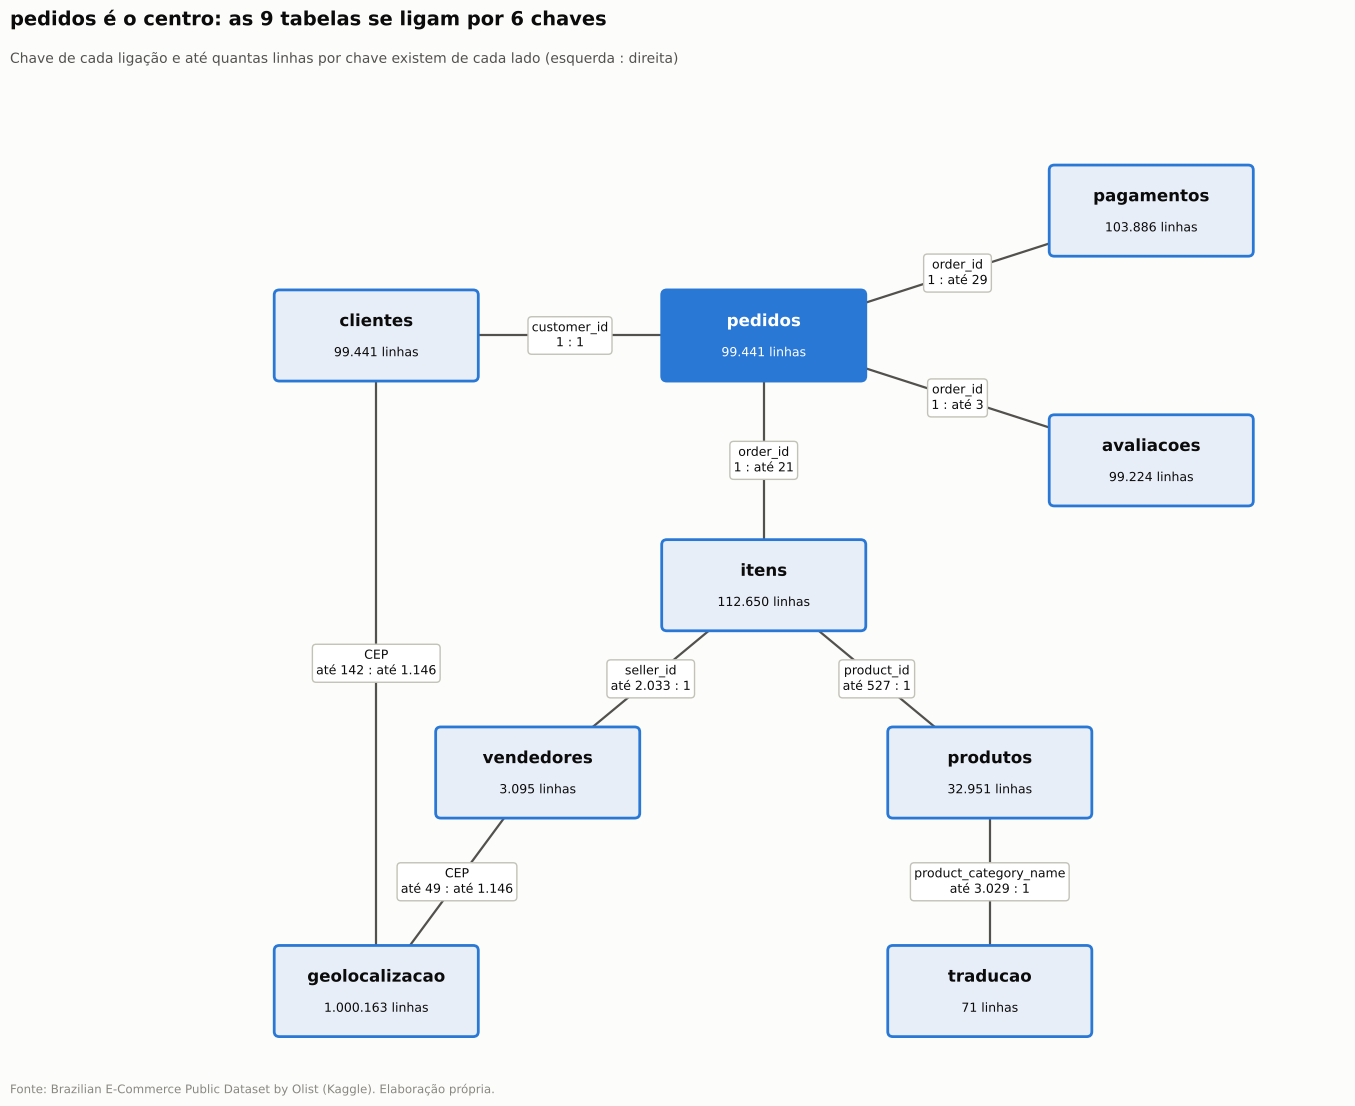

In [16]:
def caixa(ax, x, y, titulo, sub, cor="#e8eef8", cor_txt=viz.TINTA, L=3.0, A=1.3):
    ax.add_patch(FancyBboxPatch((x - L/2, y - A/2), L, A, boxstyle="round,pad=0.08",
                                fc=cor, ec=viz.DESTAQUE, lw=2, zorder=3))
    ax.text(x, y + 0.22, titulo, ha="center", va="center", fontsize=12, weight="bold", color=cor_txt, zorder=4)
    ax.text(x, y - 0.28, sub, ha="center", va="center", fontsize=9, color=cor_txt, zorder=4)

def titulo_diagrama(fig, titulo, subtitulo):
    fig.text(0.01, 0.985, titulo, fontsize=14, weight="bold", color=viz.TINTA, va="top")
    fig.text(0.01, 0.95, subtitulo, fontsize=10, color=viz.TINTA_SECUNDARIA, va="top")

posicoes = {
    "clientes": (-6.0, 2.0), "pedidos": (0.0, 2.0), "pagamentos": (6.0, 4.0),
    "avaliacoes": (6.0, 0.0), "itens": (0.0, -2.0), "vendedores": (-3.5, -5.0),
    "produtos": (3.5, -5.0), "traducao": (3.5, -8.5), "geolocalizacao": (-6.0, -8.5),
}

fig, ax = plt.subplots(figsize=(15, 12))
ax.set_xlim(-9, 9); ax.set_ylim(-9.6, 5.2); ax.axis("off")
for nome, (x, y) in posicoes.items():
    centro = nome == "pedidos"
    caixa(ax, x, y, nome, f"{fmt(len(bases[nome]))} linhas",
          cor=viz.DESTAQUE if centro else "#e8eef8", cor_txt="white" if centro else viz.TINTA)

for esq, dir_, ch_esq, ch_dir, n_esq, n_dir, *_ in LIGACOES:
    (xo, yo), (xd, yd) = posicoes[n_esq], posicoes[n_dir]
    ax.plot([xo, xd], [yo, yd], color=viz.TINTA_SECUNDARIA, lw=1.6, zorder=2)
    m_esq, m_dir = esq[ch_esq].value_counts().max(), dir_[ch_dir].value_counts().max()
    lado = lambda m: "1" if m == 1 else f"até {fmt(m)}"
    card = f"{lado(m_esq)} : {lado(m_dir)}"
    chave = "CEP" if "zip" in ch_esq else ch_esq
    ax.text((xo + xd) / 2, (yo + yd) / 2, f"{chave}\n{card}", ha="center", va="center", fontsize=9, zorder=5,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=viz.CONTEXTO))

titulo_diagrama(fig, "pedidos é o centro: as 9 tabelas se ligam por 6 chaves",
                "Chave de cada ligação e até quantas linhas por chave existem de cada lado (esquerda : direita)")
viz.fonte(fig)
viz.salvar_figura(fig, "01_mapa_tabelas")
plt.show()

**Leitura:**

| No desenho | O que significa | Consequência |
|---|---|---|
| Caixa azul (`pedidos`) | É o centro do modelo; todas as ligações partem dela, direta ou indiretamente | O pedido é a unidade principal do estudo |
| "1 : até N" (itens, pagamentos, avaliações) | Um pedido tem várias linhas do outro lado | Essas tabelas são resumidas por `order_id` antes do merge |
| "até N : 1" (produtos, vendedores) | Muitos itens apontam para o mesmo produto ou vendedor, que aparece uma vez no cadastro | Podem ser juntados direto |
| CEP → geolocalização | Muitas linhas dos dois lados para o mesmo CEP | A geolocalização vira 1 coordenada por CEP (decisão D8) |

## 6. Correlação entre as variáveis numéricas (P5)
Ainda antes da junção final, o estudo verifica quais números andam juntos. A **correlação** vai de −1 a +1: perto de +1, quando um sobe o outro também sobe; perto de 0, não há relação; perto de −1, quando um sobe o outro desce.

A análise é feita no nível do **item**, que é onde preço, frete, peso e volume nascem juntos. O volume é calculado como comprimento × altura × largura.

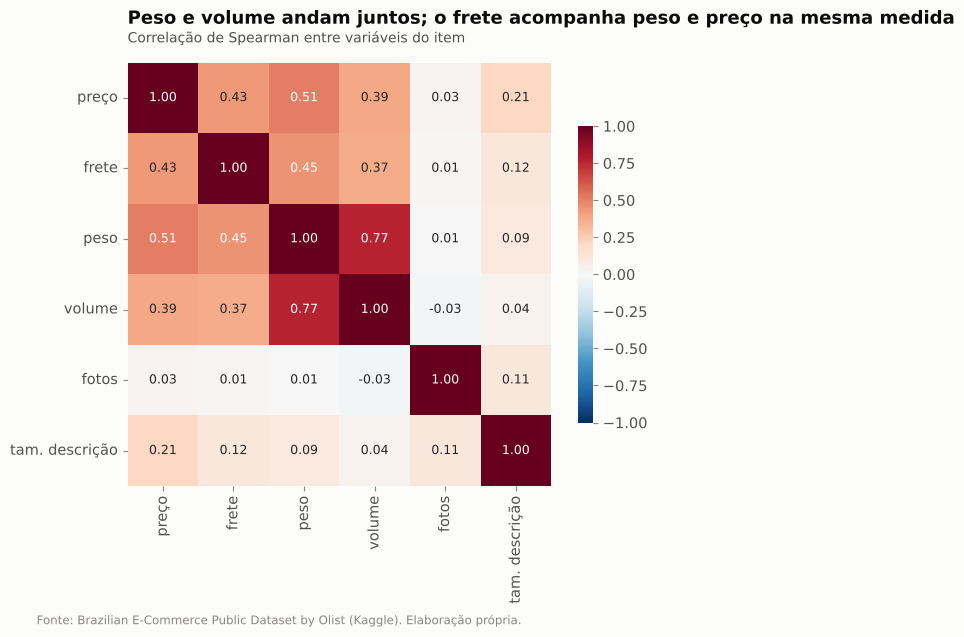

In [17]:
num = itens_raw.merge(produtos, on="product_id", how="left")
num["volume_cm3"] = num["product_length_cm"] * num["product_height_cm"] * num["product_width_cm"]
num = num[["price", "freight_value", "product_weight_g", "volume_cm3", "product_photos_qty", "product_description_lenght"]]
num.columns = ["preço", "frete", "peso", "volume", "fotos", "tam. descrição"]
corr = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.7}, ax=ax, annot_kws={"size": 9})
ax.grid(False)
viz.titulo(ax, "Peso e volume andam juntos; o frete acompanha peso e preço na mesma medida",
           "Correlação de Spearman entre variáveis do item")
viz.fonte(fig)
viz.salvar_figura(fig, "01_correlacao")
plt.show()

**Leitura (P5):** foi usada a correlação de **Spearman**, que compara a **ordem** dos valores (quem é maior que quem) em vez do valor em si. Ela é menos afetada pelos poucos itens muito caros ou muito pesados do que a de Pearson.

| Par de variáveis | Correlação | Interpretação |
|---|---|---|
| Peso × volume | **0,77** | As mais ligadas, como esperado: produto grande costuma ser pesado |
| Frete × peso / preço / volume | 0,45 / 0,43 / 0,37 | Relação moderada: nenhuma delas explica o frete sozinha, o que justifica olhar a **distância** no notebook 03 |
| Fotos e tamanho da descrição × resto | perto de 0 | Praticamente não se relacionam com nada |

Correlação não é causa: o mapa de calor mostra quais variáveis andam juntas, não qual provoca a outra.

## 7. Outras inconsistências encontradas (P6)
Além dos nulos, três problemas mudam os números se não forem tratados: meses incompletos, datas fora de ordem e a forma de identificar o cliente.

### 7.1 Meses incompletos, datas trocadas e identificação do cliente
O painel abaixo mostra os três problemas, um em cada gráfico.

Pedidos postados antes de serem aprovados: 1.359
customer_id distintos: 99.441 · pessoas (customer_unique_id): 96.096


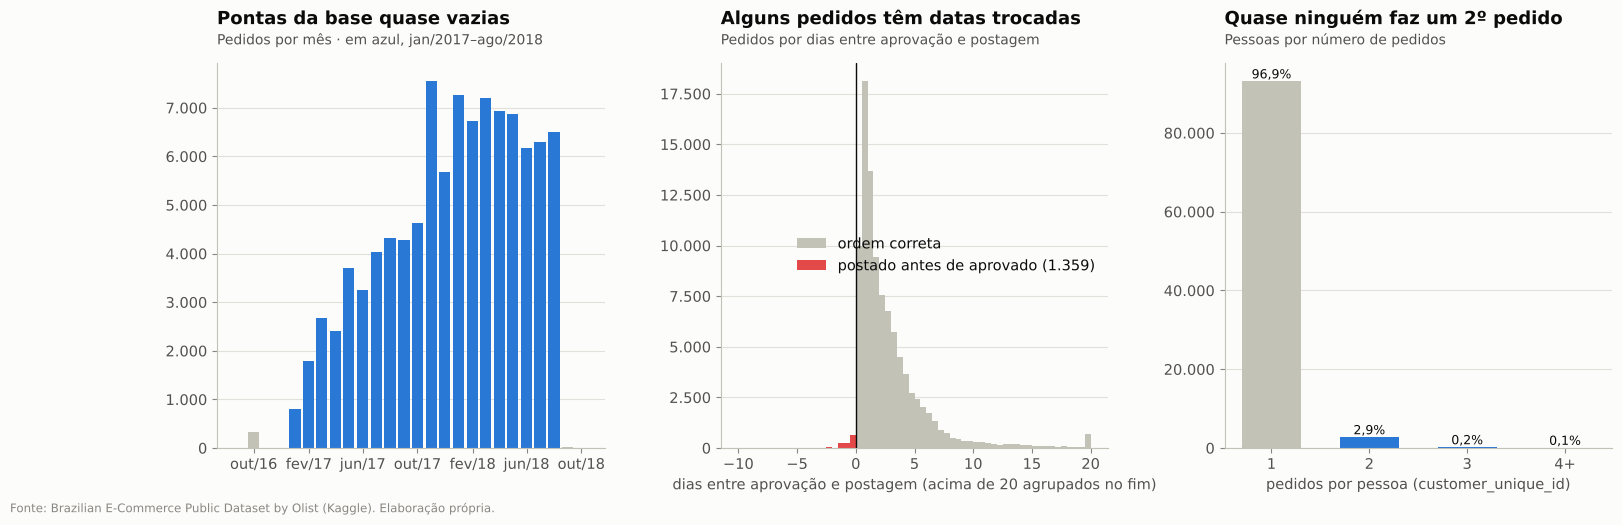

In [18]:
for col in dados.COLUNAS_DATA["pedidos"]:
    pedidos_raw[col] = pd.to_datetime(pedidos_raw[col])

por_mes = pedidos_raw.groupby(pedidos_raw["order_purchase_timestamp"].dt.to_period("M")).size()
postou_antes = (pedidos_raw["order_delivered_carrier_date"] < pedidos_raw["order_approved_at"]).sum()

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 1) pedidos por mês: dentro da janela em azul, fora em cinza
ax = axs[0]
meses = por_mes.index.to_timestamp()
na_janela = (meses >= config.INICIO_JANELA) & (meses <= config.FIM_JANELA)
ax.bar(meses, por_mes.values, width=25, color=np.where(na_janela, viz.DESTAQUE, viz.CONTEXTO))
viz.titulo(ax, "Pontas da base quase vazias", "Pedidos por mês · em azul, jan/2017–ago/2018")
viz.eixo_mensal(ax, 4)

# 2) dias entre aprovação e postagem: negativo = postou antes de aprovar
ax = axs[1]
dias = (pedidos_raw["order_delivered_carrier_date"] - pedidos_raw["order_approved_at"]).dt.total_seconds() / 86400
dias = dias.dropna().clip(-10, 20)
bins = np.arange(-10, 20.5, 0.5)
ax.hist(dias[dias >= 0], bins=bins, color=viz.CONTEXTO, label="ordem correta")
ax.hist(dias[dias < 0], bins=bins, color=viz.ALERTA, label=f"postado antes de aprovado ({fmt(postou_antes)})")
ax.axvline(0, color=viz.TINTA, lw=1)
ax.set_xlabel("dias entre aprovação e postagem (acima de 20 agrupados no fim)")
ax.legend(loc="center right")
viz.titulo(ax, "Alguns pedidos têm datas trocadas", "Pedidos por dias entre aprovação e postagem")

# 3) quantos pedidos cada pessoa fez
ax = axs[2]
por_pessoa = (pedidos_raw.merge(clientes[["customer_id", "customer_unique_id"]], on="customer_id")
              .groupby("customer_unique_id").size().clip(upper=4).value_counts().sort_index())
barras = ax.bar(["1", "2", "3", "4+"][:len(por_pessoa)], por_pessoa.values,
                color=[viz.CONTEXTO] + [viz.DESTAQUE] * (len(por_pessoa) - 1), width=0.6)
for b, v in zip(barras, por_pessoa.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v / por_pessoa.sum():.1%}".replace(".", ","),
            ha="center", va="bottom", fontsize=9)
ax.set_xlabel("pedidos por pessoa (customer_unique_id)")
viz.titulo(ax, "Quase ninguém faz um 2º pedido", "Pessoas por número de pedidos")

for a in axs:
    a.yaxis.set_major_formatter(plt.FuncFormatter(viz.formato_milhar))
fig.subplots_adjust(wspace=0.3)
viz.fonte(fig)
viz.salvar_figura(fig, "01_inconsistencias")
plt.show()

print(f"Pedidos postados antes de serem aprovados: {fmt(postou_antes)}")
print(f"customer_id distintos: {fmt(clientes['customer_id'].nunique())} · "
      f"pessoas (customer_unique_id): {fmt(clientes['customer_unique_id'].nunique())}")

**Leitura (P6):**

| Gráfico | O que aparece | Decisão |
|---|---|---|
| **Meses incompletos** (esquerda) | 2016 e set–out/2018 quase não têm pedidos. É um corte da extração dos dados, não uma queda do negócio | **D1:** as análises no tempo usam só **jan/2017 a ago/2018** (20 meses completos) |
| **Datas trocadas** (centro) | Todo pedido segue a ordem compra → aprovação → postagem → entrega. Em 1.359 pedidos (1,4%), a postagem aparece **antes** da aprovação, o que não acontece na prática: é erro de registro | **D7:** descarta-se só o tempo daquela etapa; o pedido continua na base e o prazo total (compra → entrega) segue válido |
| **Cliente** (direita) | O `customer_id` muda a cada pedido, então contar recompra por ele daria zero. Pelo `customer_unique_id`, **96,9% das pessoas fizeram um único pedido** | **D5:** cliente = `customer_unique_id`. É o primeiro sinal do problema de recompra estudado no notebook 04 |

### 7.2 O mesmo produto com preços diferentes é outlier?
Na seção 5.1, o mesmo `product_id` aparece com preços diferentes. Num marketplace isso é normal: vendedores diferentes vendem o mesmo produto, e o preço muda com o tempo (promoções, Black Friday).

Um **outlier** é um valor fora da curva. Para separar a variação normal de um valor estranho, cada venda é comparada com a **mediana de preço do próprio produto**. A mediana é o valor do meio quando os preços são colocados em fila, e não é puxada por um preço muito alto ou muito baixo.

In [19]:
precos = itens_raw.groupby("product_id")["price"].agg(["nunique", "count"])
varia = (precos["nunique"] > 1).mean()

mediana = itens_raw.groupby("product_id")["price"].transform("median")
razao = itens_raw["price"] / mediana
suspeitos = itens_raw[(razao < 0.5) | (razao > 2)]

print(f"Produtos vendidos mais de uma vez: {fmt((precos['count'] > 1).sum())}")
print(f"Produtos com mais de um preço: {pct_br(varia)} de todos os produtos")
print(
    "Vendas abaixo da metade ou acima do dobro da mediana do produto: "
    f"{fmt(len(suspeitos))} ({pct_br(len(suspeitos) / len(itens_raw), 2)} das vendas)"
)
display(
    suspeitos.assign(mediana_produto=mediana, razao=razao.round(2))
    [["order_id", "product_id", "seller_id", "price", "mediana_produto", "razao"]]
    .head(10)
)

,order_id,product_id,seller_id,price,mediana_produto,razao
2826,065c05543ebdfd79fb629b2b4a6ab904,2eb384017334e47db9ccf364216799df,98dac6635aee4995d501a3972e047414,88.50,21.150,4.18
4050,0916594b6973230f69379f83d3bac036,b72e2daf4a916d46eb0076071027d05b,e5a3438891c0bfdb9394643f95273d8e,13.99,33.600,0.42
4225,09859a28d56f326d009da66f7d02e99d,ba16581014183c8415da15145f3d4c24,710e3548e02bc1d2831dfc4f1b5b14d4,299.00,629.495,0.47
6899,0f9db6b2900040157d27f21ae0f3d86d,c9c6fde711572c1ad99ca12728c6af00,562fc2f2c2863ab7e79a9e4388a58a14,59.99,29.990,2.00
8032,12376b5a59bae892cd083a87b57c0bc0,8c70c4455a59267e8e2ddf800792d77b,e9bc59e7b60fc3063eb2290deda4cced,99.90,199.900,0.50
11769,1ab4c41692b49393c880bd70c3cbc09c,b88182b83c726595532324fd84ac7db4,b4ffb71f0cb1b1c3d63fad021ecf93e1,19.00,9.200,2.07
11815,1ad01d500af41c23f0f84509df94f797,500870614ddcf5bd84f7d26861026c8a,ef506c96320abeedfb894c34db06f478,34.99,14.000,2.50
12774,1cf13598b7e6449603960c24184dee24,3ac52f93c2299daa201fbb7ff36546f7,7e3f87d16fb353f408d467e74fbd8014,16.55,43.890,0.38
14012,1fea99244761fe0359d759672fdbcf4a,2fea0f2cec6b6324a277d4a61c2ed2c6,beadbee30901a7f61d031b6b686095ad,86.00,35.000,2.46
14226,205d5db88d0a8b3736d1afa2f6a329c5,d97cfa719a6198d4a66453e0c6ed596c,e5a3438891c0bfdb9394643f95273d8e,73.90,34.300,2.15


Produtos vendidos mais de uma vez: 14.834
Produtos com mais de um preço: 17,9% de todos os produtos
Vendas abaixo da metade ou acima do dobro da mediana do produto: 101 (0,09% das vendas)


**Leitura (P6):**

| Medida | Resultado | Interpretação |
|---|---|---|
| Produtos com mais de um preço | 17,9% dos produtos | Variação comum num marketplace: outro vendedor ou outra data |
| Vendas fora da faixa de 0,5× a 2× a mediana do produto | 101 vendas (0,09%) | Fração mínima, sem efeito nas conclusões de receita |

**Decisão D3:** não há remoção de outliers de preço. O preço considerado é sempre o **da venda** (tabela de itens), nunca um preço de cadastro.

## 8. Montagem das duas bases (P7)
Com tudo o que foi visto acima, a regra do merge é uma só: **resumir antes de juntar** tudo o que tem mais de uma linha por chave.

Exemplo do porquê: se um pedido com 3 itens fosse juntado direto com os seus 2 pagamentos, viraria 6 linhas, e a receita apareceria repetida. Resumindo primeiro (1 linha de itens e 1 linha de pagamentos por pedido), o pedido continua sendo 1 linha só.

O dicionário `t` reúne as 9 tabelas já carregadas na memória (sem reler os arquivos), com as datas convertidas. A lógica completa está em `src/dados.py`; abaixo, o passo a passo da base de pedidos mostra o que entra em cada etapa.

In [20]:
t = {
    "clientes": clientes, "pedidos": pedidos_raw, "itens": itens_raw, "pagamentos": pagamentos,
    "avaliacoes": avaliacoes, "produtos": produtos, "vendedores": vendedores,
    "geolocalizacao": geo, "traducao_categorias": traducao,
}
t = {nome: df.copy() for nome, df in t.items()}
for nome, colunas in dados.COLUNAS_DATA.items():
    for col in colunas:
        t[nome][col] = pd.to_datetime(t[nome][col])

n_pedidos = len(t["pedidos"])

passo = t["pedidos"].merge(t["clientes"], on="customer_id", how="left")
print(f"pedidos + clientes:                {passo.shape}")

itens_por_pedido = t["itens"].groupby("order_id").agg(qtd_itens=("order_item_id", "count"),
                                                      valor_produtos=("price", "sum"),
                                                      valor_frete=("freight_value", "sum"))
passo = passo.merge(itens_por_pedido, on="order_id", how="left")
print(f"+ itens resumidos por pedido:       {passo.shape}")

pagto_por_pedido = t["pagamentos"].groupby("order_id").agg(valor_pago=("payment_value", "sum"))
passo = passo.merge(pagto_por_pedido, on="order_id", how="left")
print(f"+ pagamentos resumidos por pedido:  {passo.shape}")

aval_por_pedido = dados.avaliacao_por_pedido(t["avaliacoes"])
passo = passo.merge(aval_por_pedido[["order_id", "review_score"]], on="order_id", how="left")
print(f"+ 1 avaliação por pedido:           {passo.shape}")

assert len(passo) == n_pedidos, "algum merge duplicou pedidos"
print(f"\nAs linhas continuaram {fmt(n_pedidos)} em todos os passos: nenhum pedido duplicou.")

pedidos + clientes:                (99441, 12)
+ itens resumidos por pedido:       (99441, 15)
+ pagamentos resumidos por pedido:  (99441, 16)
+ 1 avaliação por pedido:           (99441, 17)

As linhas continuaram 99.441 em todos os passos: nenhum pedido duplicou.


In [21]:
# bases completas, com todas as colunas calculadas (prazos, atraso, recompra, distância)
itens = dados.construir_itens(t)
pedidos = dados.construir_pedidos(t, itens)

assert len(itens) == len(t["itens"]), "o merge dos itens perdeu ou duplicou linhas"
assert len(pedidos) == len(t["pedidos"]) and pedidos["order_id"].is_unique, "pedido duplicado"
assert abs(pedidos["gmv"].sum() - (t["itens"]["price"].sum() + t["itens"]["freight_value"].sum())) < 0.01, \
    "receita não bate com o CSV original"
print(f"base pedidos: {pedidos.shape} · base itens: {itens.shape} · checagens ok")

base pedidos: (99441, 43) · base itens: (112650, 21) · checagens ok


**Leitura:** as três checagens funcionam como um "confere" de caixa no fim do dia. Elas garantem que:
1. nenhum pedido se perdeu na junção;
2. nenhum pedido ficou duplicado;
3. a receita total da base final é **idêntica** à soma de preço + frete do CSV original.

Se qualquer uma falhar, o notebook para com erro, em vez de seguir com um número errado.

### 8.1 Fluxograma das duas bases finais
Cada base parte de uma tabela que define o que é **uma linha** (o **grão**) e recebe as demais pela chave. Na base de pedidos, 1 linha = 1 pedido; na base de itens, 1 linha = 1 item vendido.

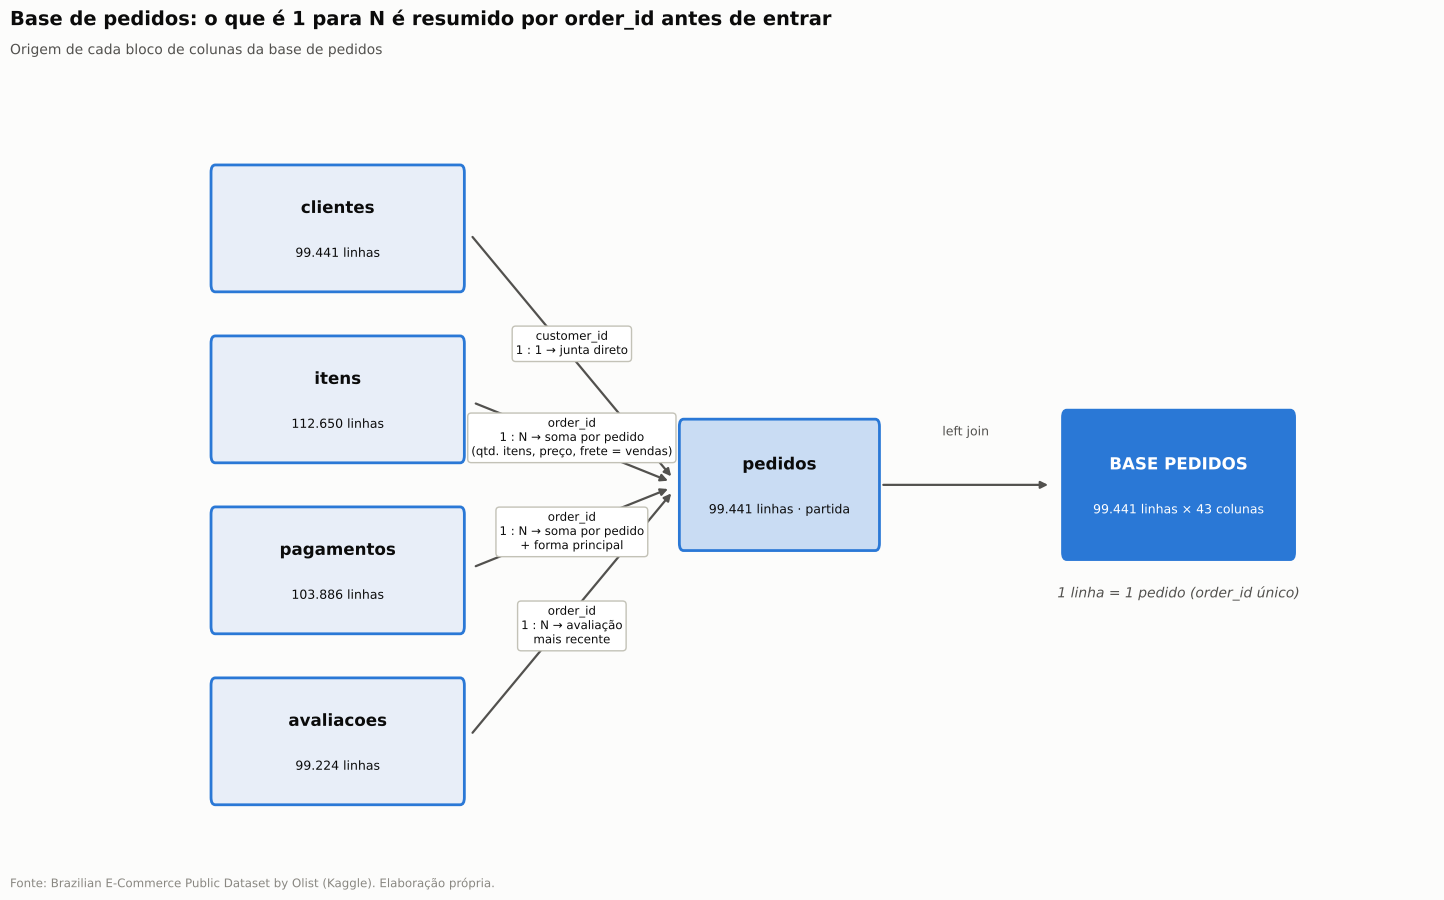

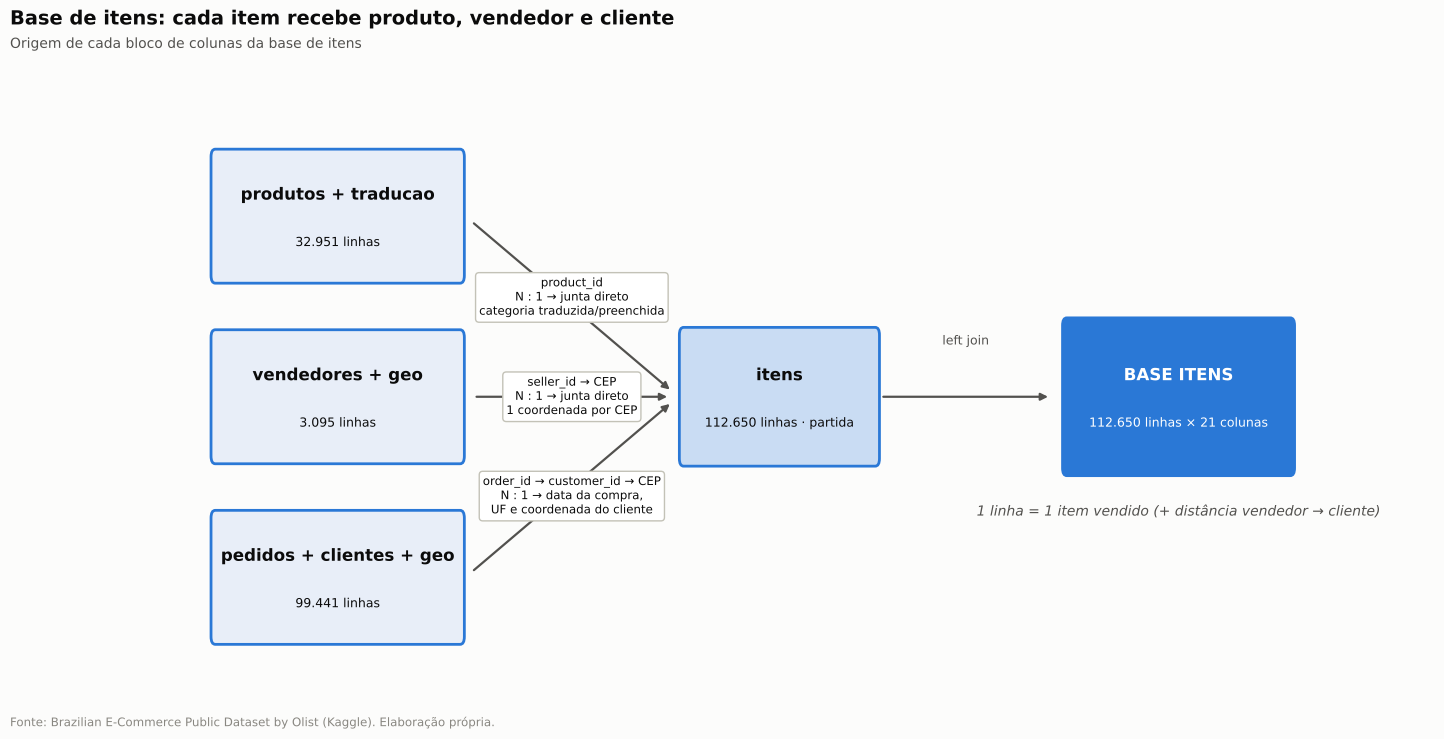

In [22]:
def fluxograma_base(titulo, subtitulo, partida, entradas, final_nome, final_df, grao, arquivo):
    n = len(entradas)
    fig, ax = plt.subplots(figsize=(16, 1.8 * n + 2.5))
    ys = [(n - 1) / 2 * 1.9 - i * 1.9 for i in range(n)]
    ax.set_xlim(-0.5, 22.8); ax.set_ylim(min(ys) - 1.3, max(ys) + 1.3); ax.axis("off")
    for (nome, df, chave, tratamento), y in zip(entradas, ys):
        caixa(ax, 2.2, y, nome, f"{fmt(len(df))} linhas", L=4.6, A=1.25)
        ax.annotate("", xy=(8.6, 0), xytext=(4.6, y), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=viz.TINTA_SECUNDARIA, lw=1.6, shrinkA=8, shrinkB=8))
        ax.text(6.6, y * 0.55, f"{chave}\n{tratamento}", ha="center", va="center", fontsize=8.5, zorder=5,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=viz.CONTEXTO))
    caixa(ax, 10.5, 0, partida[0], f"{fmt(len(partida[1]))} linhas · partida", cor="#c9dcf3", L=3.6)
    ax.annotate("", xy=(15.6, 0), xytext=(12.4, 0), zorder=2,
                arrowprops=dict(arrowstyle="-|>", color=viz.TINTA_SECUNDARIA, lw=1.6))
    ax.text(14, 0.55, "left join", ha="center", fontsize=9, color=viz.TINTA_SECUNDARIA)
    caixa(ax, 18, 0, final_nome, f"{fmt(final_df.shape[0])} linhas × {final_df.shape[1]} colunas",
          cor=viz.DESTAQUE, cor_txt="white", L=4.2, A=1.5)
    ax.text(18, -1.25, grao, ha="center", fontsize=10, style="italic", color=viz.TINTA_SECUNDARIA)
    titulo_diagrama(fig, titulo, subtitulo)
    viz.fonte(fig)
    viz.salvar_figura(fig, arquivo)
    plt.show()

fluxograma_base(
    "Base de pedidos: o que é 1 para N é resumido por order_id antes de entrar",
    "Origem de cada bloco de colunas da base de pedidos",
    partida=("pedidos", t["pedidos"]),
    entradas=[
        ("clientes",   t["clientes"],   "customer_id", "1 : 1 → junta direto"),
        ("itens",      t["itens"],      "order_id",    "1 : N → soma por pedido\n(qtd. itens, preço, frete = vendas)"),
        ("pagamentos", t["pagamentos"], "order_id",    "1 : N → soma por pedido\n+ forma principal"),
        ("avaliacoes", t["avaliacoes"], "order_id",    "1 : N → avaliação\nmais recente"),
    ],
    final_nome="BASE PEDIDOS", final_df=pedidos,
    grao="1 linha = 1 pedido (order_id único)", arquivo="01_fluxo_base_pedidos",
)

fluxograma_base(
    "Base de itens: cada item recebe produto, vendedor e cliente",
    "Origem de cada bloco de colunas da base de itens",
    partida=("itens", t["itens"]),
    entradas=[
        ("produtos + traducao",      t["produtos"],   "product_id",
         "N : 1 → junta direto\ncategoria traduzida/preenchida"),
        ("vendedores + geo",         t["vendedores"], "seller_id → CEP",
         "N : 1 → junta direto\n1 coordenada por CEP"),
        ("pedidos + clientes + geo", t["pedidos"],    "order_id → customer_id → CEP",
         "N : 1 → data da compra,\nUF e coordenada do cliente"),
    ],
    final_nome="BASE ITENS", final_df=itens,
    grao="1 linha = 1 item vendido (+ distância vendedor → cliente)", arquivo="01_fluxo_base_itens",
)

**Leitura:**

| Base | Ponto de partida | Como as outras tabelas entram |
|---|---|---|
| **Pedidos** | `pedidos`, já com 1 linha por pedido | Itens, pagamentos e avaliações entram **resumidos por `order_id`**, por isso o total de linhas não muda |
| **Itens** | `itens`, com 1 linha por item | As tabelas que entram têm uma linha só por chave (um produto, um vendedor, um pedido), então o merge é direto |
| Geolocalização | — | Entra nas duas pontas da base de itens, no vendedor e no cliente. É o que permite calcular a distância da entrega |

### 8.2 Base `pedidos`: 1 linha por pedido
É a base usada na maior parte do estudo: receita, prazo, atraso, nota e recompra.

In [23]:
display(pedidos.head())
display(pedidos.tail())

,order_id,customer_unique_id,customer_id,uf_cliente,cidade_cliente,regiao_cliente,order_status,gerou_venda,entregue,na_janela,mes,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,qtd_itens,qtd_vendedores,valor_produtos,valor_frete,gmv,frete_pct_produtos,valor_pago,parcelas,pagamento_principal,categoria_principal,vendedor_principal,uf_vendedor_principal,distancia_km,peso_total_g,dias_entrega,prazo_prometido_dias,dias_aprovacao,dias_ate_postagem,dias_transporte,dias_atraso,atrasado,data_inconsistente,review_score,avaliacao_ruim,tem_comentario,ordem_compra_cliente,cliente_recorrente
0,2e7a8482f6fb09756ca50c10d7bfc047,b7d76e111c89f7ebf14761390f0f7d17,08c5351a6aca1c1589a38f244edeee9d,RR,boa vista,Norte,shipped,True,False,False,2016-09-01,2016-09-04 21:15:19,2016-10-07 13:18:03,2016-10-18 13:14:51,NaT,2016-10-20,2.0,1.0,72.89,63.34,136.23,0.868981,136.23,1.0,credit_card,moveis decoracao,1554a68530182680ad5c8b042c3ab563,MG,3198.818994,3200.0,NaN,NaN,32.668565,10.997778,NaN,NaN,<NA>,False,1.0,True,True,1,False
1,e5fa5a7210941f7d56d0208e4e071d35,4854e9b3feff728c13ee5fc7d1547e92,683c54fc24d40ee9f8a6fc179fd9856c,RS,passo fundo,Sul,canceled,False,False,False,2016-09-01,2016-09-05 00:15:34,2016-10-07 13:17:15,NaT,NaT,2016-10-28,1.0,1.0,59.50,15.56,75.06,0.261513,75.06,3.0,credit_card,telefonia,a425f92c199eb576938df686728acd20,PR,437.134129,700.0,NaN,NaN,32.542836,NaN,NaN,NaN,<NA>,False,1.0,True,True,1,False
2,809a282bbd5dbcabb6f2f724fca862ec,009b0127b727ab0ba422f6d9604487c7,622e13439d6b5a0b486c435618b2679e,SP,sao jose dos campos,Sudeste,canceled,False,False,False,2016-09-01,2016-09-13 15:24:19,2016-10-07 13:16:46,NaT,NaT,2016-09-30,NaN,NaN,NaN,NaN,NaN,NaN,40.95,2.0,credit_card,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.911424,NaN,NaN,NaN,<NA>,False,1.0,True,True,1,False
3,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,86dc2ffce2dfff336de2f386a786e574,SP,sao joaquim da barra,Sudeste,delivered,True,True,False,2016-09-01,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,3.0,1.0,134.97,8.49,143.46,0.062903,NaN,NaN,NaN,beleza saude,ecccfa2bb93b34a3bf033cc5d1dcdc69,PR,566.040211,3000.0,54.813194,18.488449,0.000000,53.205035,1.60816,36.0,True,False,1.0,True,True,1,False
4,71303d7e93b399f5bcd537d124c0bcfa,0eb1ee9dba87f5b36b4613a65074337c,b106b360fe2ef8849fbbd056f777b4d5,SP,sao paulo,Sudeste,canceled,False,False,False,2016-10-01,2016-10-02 22:07:52,2016-10-06 15:50:56,NaT,NaT,2016-10-25,1.0,1.0,100.00,9.34,109.34,0.093400,109.34,1.0,credit_card,bebes,25e6ffe976bd75618accfe16cefcbd0d,SP,10.175818,500.0,NaN,NaN,3.738241,NaN,NaN,NaN,<NA>,False,1.0,True,False,1,False


,order_id,customer_unique_id,customer_id,uf_cliente,cidade_cliente,regiao_cliente,order_status,gerou_venda,entregue,na_janela,mes,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,qtd_itens,qtd_vendedores,valor_produtos,valor_frete,gmv,frete_pct_produtos,valor_pago,parcelas,pagamento_principal,categoria_principal,vendedor_principal,uf_vendedor_principal,distancia_km,peso_total_g,dias_entrega,prazo_prometido_dias,dias_aprovacao,dias_ate_postagem,dias_transporte,dias_atraso,atrasado,data_inconsistente,review_score,avaliacao_ruim,tem_comentario,ordem_compra_cliente,cliente_recorrente
99436,392ed9afd714e3c74767d0c4d3e3f477,9bb92bebd4cb7511e1a02d5e50bc4655,2823ffda607a2316375088e0d00005ec,SP,guarulhos,Sudeste,canceled,False,False,False,2018-09-01,2018-09-29 09:13:03,NaT,NaT,NaT,2018-10-15,NaN,NaN,NaN,NaN,NaN,NaN,137.03,1.0,voucher,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,False,1.0,True,True,1,False
99437,616fa7d4871b87832197b2a137a115d2,634420a0ea42302205032ed44ac7fccc,bf6181a85bbb4115736c0a8db1a53be3,RJ,pirai,Sudeste,canceled,False,False,False,2018-10-01,2018-10-01 15:30:09,NaT,NaT,NaT,2018-10-23,NaN,NaN,NaN,NaN,NaN,NaN,80.38,1.0,voucher,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,False,2.0,True,False,2,True
99438,a2ac6dad85cf8af5b0afb510a240fe8c,af5454198a97379394cacf676e1e96cb,4c2ec60c29d10c34bd49cb88aa85cfc4,SP,registro,Sudeste,canceled,False,False,False,2018-10-01,2018-10-03 18:55:29,NaT,NaT,NaT,2018-10-16,NaN,NaN,NaN,NaN,NaN,NaN,197.55,1.0,voucher,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,False,1.0,True,True,3,True
99439,b059ee4de278302d550a3035c4cdb740,262e1f1e26e92e86375f86840b4ffd63,856336203359aa6a61bf3826f7d84c49,PI,picos,Nordeste,canceled,False,False,False,2018-10-01,2018-10-16 20:16:02,NaT,NaT,NaT,2018-11-12,NaN,NaN,NaN,NaN,NaN,NaN,222.03,1.0,voucher,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,False,5.0,False,True,2,True
99440,10a045cdf6a5650c21e9cfeb60384c16,87ab9fec999db8bd5774917de3cdf01c,a4b417188addbc05b26b72d5e44837a1,SP,sorocaba,Sudeste,canceled,False,False,False,2018-10-01,2018-10-17 17:30:18,NaT,NaT,NaT,2018-10-30,NaN,NaN,NaN,NaN,NaN,NaN,89.71,1.0,voucher,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,False,1.0,True,True,1,False


### 8.3 Base `itens`: 1 linha por item vendido
É a base usada quando o detalhe importa: categoria, vendedor, distância e frete de cada item.

In [24]:
display(itens.head())
display(itens.tail())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,preco,frete,categoria,categoria_en,categoria_original,peso_g,volume_cm3,product_photos_qty,uf_vendedor,cidade_vendedor,customer_unique_id,uf_cliente,order_purchase_timestamp,distancia_km,mesmo_estado,frete_pct_preco
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool stuff,cool_stuff,cool_stuff,650.0,3528.0,4.0,SP,volta redonda,871766c5855e863f6eccc05f988b23cb,RJ,2017-09-13 08:59:02,301.229205,False,0.225637
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet shop,pet_shop,pet_shop,30000.0,60000.0,2.0,SP,sao paulo,eb28e67c4c0b83846050ddfb8a35d051,SP,2017-04-26 10:53:06,588.404069,True,0.083076
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis decoracao,furniture_decor,moveis_decoracao,3050.0,14157.0,2.0,MG,borda da mata,3818d81c6709e39d06b2738a8d3a2474,MG,2018-01-14 14:33:31,312.835023,True,0.089799
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery,perfumaria,200.0,2400.0,1.0,SP,franca,af861d436cfc08b2c2ddefd0ba074622,SP,2018-08-08 10:00:35,295.032480,True,0.984604
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas jardim,garden_tools,ferramentas_jardim,3750.0,42000.0,1.0,PR,loanda,64b576fb70d441e8f1b2d7d446e483c5,SP,2017-02-04 13:57:51,646.468544,False,0.090745


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,preco,frete,categoria,categoria_en,categoria_original,peso_g,volume_cm3,product_photos_qty,uf_vendedor,cidade_vendedor,customer_unique_id,uf_cliente,order_purchase_timestamp,distancia_km,mesmo_estado,frete_pct_preco
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,utilidades domesticas,housewares,utilidades_domesticas,10150.0,53400.0,3.0,SC,itajai,0c9aeda10a71f369396d0c04dce13a64,MA,2018-04-23 13:57:06,2754.963891,False,0.144705
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,informatica acessorios,computers_accessories,informatica_acessorios,8950.0,44460.0,1.0,SP,sao paulo,0da9fe112eae0c74d3ba1fe16de0988b,PR,2018-07-14 10:26:46,349.700399,False,0.104371
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,esporte lazer,sports_leisure,esporte_lazer,967.0,9576.0,1.0,PR,curitiba,cd79b407828f02fdbba457111c38e4c4,SP,2017-10-23 17:07:56,339.250310,False,0.169670
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,informatica acessorios,computers_accessories,informatica_acessorios,100.0,8000.0,1.0,SP,sao paulo,eb803377c9315b564bdedad672039306,SP,2017-08-14 23:02:59,72.609525,True,0.155742
112649,fffe41c64501cc87c801fd61db3f6244,1,350688d9dc1e75ff97be326363655e01,f7ccf836d21b2fb1de37564105216cc1,2018-06-12 17:10:13,43.00,12.79,cama mesa banho,bed_bath_table,cama_mesa_banho,600.0,1710.0,1.0,SP,ibitinga,cd76a00d8e3ca5e6ab9ed9ecb6667ac4,SP,2018-06-09 17:00:18,134.908905,True,0.297442


## 9. Salvamento das bases finais (P7)
As duas bases são salvas em `data/processed/`, em dois formatos, cada um com uma função:

| Formato | Arquivos | Para que serve |
|---|---|---|
| **CSV** (vírgula, ponto decimal, UTF-8) | `pedidos.csv`, `itens.csv` | Abrir e conferir em qualquer ferramenta (Excel, Power BI, outro notebook) |
| **PKL** (pickle do pandas) | `pedidos.pkl`, `itens.pkl` | Reabrir no Python **com os tipos preservados** (datas, verdadeiro/falso, inteiros). É o formato lido pelos notebooks 02 a 05 |

O CSV não guarda o tipo das colunas: uma data volta como texto e precisaria ser convertida de novo. Por isso os notebooks seguintes leem o PKL. No fim, as duas versões são reabertas e comparadas com as bases em memória.

**Importante para quem baixar o projeto:** a pasta `data/processed/` é gerada aqui. Por isso o notebook 01 precisa rodar **antes** dos outros.

In [25]:
# ============================================================
# SALVAR AS BASES PROCESSADAS (CSV + PKL)
# ============================================================

PASTA_PROCESSADOS.mkdir(parents=True, exist_ok=True)

bases_processadas = {
    "pedidos": pedidos,
    "itens": itens,
}

for nome, df in bases_processadas.items():
    caminho_csv = PASTA_PROCESSADOS / f"{nome}.csv"
    caminho_pkl = PASTA_PROCESSADOS / f"{nome}.pkl"

    df.to_csv(caminho_csv, index=False, encoding="utf-8")
    df.to_pickle(caminho_pkl)

    print(
        f"{nome:8} → {caminho_csv.relative_to(RAIZ)} e {caminho_pkl.name} "
        f"({fmt(df.shape[0])} linhas × {df.shape[1]} colunas)"
    )

# ============================================================
# CONFERIR A REABERTURA DOS ARQUIVOS
# ============================================================

for nome, df in bases_processadas.items():

    # PKL: precisa voltar idêntico, com os mesmos tipos
    relido_pkl = pd.read_pickle(PASTA_PROCESSADOS / f"{nome}.pkl")
    assert relido_pkl.equals(df), f"{nome}.pkl: conteúdo diferente da base em memória"

    # CSV: mesmas linhas e colunas, e a mesma receita
    relido_csv = pd.read_csv(PASTA_PROCESSADOS / f"{nome}.csv", low_memory=False)
    assert relido_csv.shape == df.shape, f"{nome}.csv: dimensões diferentes"

    print(f"[OK] {nome}: PKL idêntico · CSV com {fmt(relido_csv.shape[0])} linhas × {relido_csv.shape[1]} colunas")

print("\nReabertura conferida.")

pedidos  → data/processed/pedidos.csv e pedidos.pkl (99.441 linhas × 43 colunas)
itens    → data/processed/itens.csv e itens.pkl (112.650 linhas × 21 colunas)
[OK] pedidos: PKL idêntico · CSV com 99.441 linhas × 43 colunas
[OK] itens: PKL idêntico · CSV com 112.650 linhas × 21 colunas

Reabertura conferida.


## 10. Resumo das decisões (P8)

| # | O que foi encontrado | O que foi feito |
|---|---|---|
| D1 | 2016 e set–out/2018 incompletos | Análises no tempo só de jan/2017 a ago/2018 |
| D2 | Pedidos cancelados ou indisponíveis | Fora da receita |
| D3 | Itens e pagamentos têm várias linhas por pedido | Receita = preço + frete dos itens, somados por pedido antes do merge |
| D4 | Pedidos com mais de uma avaliação | Mantida a mais recente |
| D5 | `customer_id` muda a cada pedido | Cliente = `customer_unique_id` |
| D6 | Entregues sem data | Prazo só com pedido entregue e com data |
| D7 | Datas fora de ordem | Descartado só o tempo da etapa inconsistente |
| D8 | Vários pontos por CEP e alguns fora do Brasil | 1 coordenada por CEP (mediana), só dentro do Brasil |
| D9 | Produtos sem categoria e categorias sem tradução | "sem categoria" e tradução manual |

Detalhes em `docs/qualidade_dados.md`.

**Conclusão (P8):** sim, a base é confiável **depois** dos tratamentos. Os problemas encontrados são conhecidos, pequenos em volume e têm regra clara. As três checagens da seção 8 garantem que nenhum pedido se perdeu ou duplicou e que a receita bate com o arquivo original.

**Próximo:** `02_crescimento.ipynb`, que parte das bases `pedidos` e `itens` salvas aqui em `data/processed/`.